# 07 · Visión: clasificador de hojas de café (RoCoLe + BRACOL)

Notebook de **análisis**: no entrena nada. Lee los resultados que generan los scripts de `src/vision/` y los presenta con
sus tablas y figuras. Todas las cifras salen de archivos (`experiments/vision/`, `data/processed/vision/`); si se vuelve a
entrenar, basta volver a ejecutar el notebook.

Regenerar los datos de entrada:
```
python -m src.vision.datasets      # manifiesto
python -m src.vision.splits        # split sin fuga y baselines
python -m src.vision.train --config configs/vision_resnet18_dlr_both.yaml --seed 1
python -m src.vision.summarize     # media ± desviación entre semillas
python -m src.vision.finalize      # calibración, selección y exportación
python -m src.vision.validate_explanations   # Grad-CAM
```

Clases: **0 sana · 1 roya leve (≤ 5 % del área) · 2 roya severa (> 5 %) · 3 otra afección.** El test de BRACOL (arábica) es la evaluación principal.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.vision.datasets import CLASSES
from src.vision.splits import SPLITS_PATH, baselines
from src.vision.summarize import load_runs, summarize
EXP = ROOT / "experiments" / "vision"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SHORT = ["sana", "leve", "severa", "otra"]

## 1. Datos: 3,052 imágenes usables y split sin fuga

In [2]:
splits = pd.read_csv(SPLITS_PATH)
table = pd.crosstab([splits["dataset"], splits["split"]], splits["label"].map(dict(enumerate(CLASSES))))[list(CLASSES)]
display(table)
print("Imágenes usables:", len(splits))

label          sana  roya_leve  roya_severa  otra_afeccion
dataset split                                             
bracol  test     41         48           33            117
        train   190        217          153            548
        val      41         47           32            118
rocole  test    110         48           36             24
        train   536        227          160            108
        val     111         49           35             23

Imágenes usables: 3052


Baselines que el modelo debe superar (se calculan antes de entrenar). La clase mayoritaria y el azar uniforme dan un F1 macro
entre 0.12 y 0.28.

In [3]:
display(baselines(splits).round(3))

,datos,conjunto,baseline,n,accuracy,f1_macro
0,bracol,val,clase mayoritaria,238,0.496,0.166
1,bracol,val,azar uniforme,238,0.269,0.247
2,bracol,test,clase mayoritaria,239,0.490,0.164
3,bracol,test,azar uniforme,239,0.259,0.231
4,rocole,val,clase mayoritaria,218,0.509,0.169
5,rocole,val,azar uniforme,218,0.280,0.270
6,rocole,test,clase mayoritaria,218,0.505,0.168
7,rocole,test,azar uniforme,218,0.303,0.279
8,ambos,val,clase mayoritaria,456,0.333,0.125
9,ambos,val,azar uniforme,456,0.246,0.243


## 2. Ablación de estrategias de transfer learning (una corrida por configuración, semilla 42)

In [4]:
runs = load_runs()
single = runs[~runs["corrida"].str.contains(r"_s\d$")].copy()
single = single.sort_values(["entrenado_con", "modelo", "estrategia"])
display(single[["corrida", "f1_val", "bracol_f1", "rocole_f1", "bracol_recall_severa", "rocole_recall_severa"]].round(3).reset_index(drop=True))

,corrida,f1_val,bracol_f1,rocole_f1,bracol_recall_severa,rocole_recall_severa
0,efficientnet_b0_dlr_both,0.858,0.928,0.720,0.939,0.694
1,resnet18_dlr_both,0.841,0.923,0.727,0.758,0.611
2,efficientnet_b0_dlr_bracol,0.918,0.918,0.241,0.848,0.500
3,resnet18_fe_bracol,0.713,0.713,0.114,0.606,0.139
4,resnet18_dlr_bracol,0.952,0.928,0.126,0.818,0.944
5,resnet18_partial_bracol,0.867,0.865,0.159,0.758,0.972
6,small_cnn_bracol,0.818,0.862,0.202,0.970,0.306
7,resnet18_dlr_rocole,0.730,0.371,0.711,0.939,0.806


- Orden de las estrategias en BRACOL (Lab 6): solo cabeza < ajuste parcial < completo con learning rate diferencial.
- Un modelo entrenado solo con BRACOL **cae por debajo del azar en fotos de campo** (F1 ≈ 0.11–0.24 frente a 0.28), y uno entrenado
  solo con RoCoLe falla en BRACOL: hay un cambio de dominio severo. Entrenar con ambos lo resuelve.

## 3. Cuatro semillas por configuración (modelos combinados)

In [5]:
summary = summarize(runs)
both = summary.xs("both", level="entrenado_con")
cols = ["bracol_f1", "rocole_f1", "rocole_recall_severa", "rocole_sens_roya", "rocole_esp_roya"]
out = pd.concat({"media": both["media"][cols], "desv": both["desv"][cols]}, axis=1)
display(out.round(3))

media                                                                      desv                                                                
                           bracol_f1 rocole_f1 rocole_recall_severa rocole_sens_roya rocole_esp_roya bracol_f1 rocole_f1 rocole_recall_severa rocole_sens_roya rocole_esp_roya
modelo          estrategia                                                                                                                                                    
efficientnet_b0 full_dlr       0.917     0.716                0.736            0.887           0.896     0.028     0.030                0.066            0.023           0.021
resnet18        full_dlr       0.936     0.719                0.625            0.783           0.929     0.011     0.015                0.036            0.088           0.037

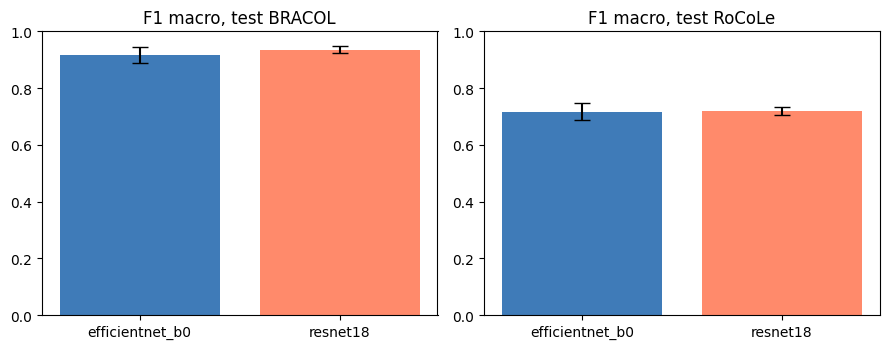

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for k, (metric, title) in enumerate([("bracol_f1", "F1 macro, test BRACOL"), ("rocole_f1", "F1 macro, test RoCoLe")]):
    means = [both.loc[m, ("media", metric)].iloc[0] for m in both.index.get_level_values("modelo")]
    stds = [both.loc[m, ("desv", metric)].iloc[0] for m in both.index.get_level_values("modelo")]
    ax[k].bar(both.index.get_level_values("modelo"), means, yerr=stds, capsize=6, color=["#3F7BB8", "#FF8A6B"])
    ax[k].set_title(title); ax[k].set_ylim(0, 1)
plt.tight_layout(); plt.show()

ResNet-18 y EfficientNet-B0 **empatan**: las diferencias son menores o comparables a la desviación entre semillas. La
sensibilidad de roya en campo de ResNet-18 varía mucho entre semillas (ver `desv`), por eso no se reporta una sola semilla.

## 4. Selección final y calibración

In [7]:
final = pd.read_csv(EXP / "final_comparison.csv")
display(final[["candidato", "miembros", "val_nll_calibrado", "val_f1", "bracol_f1", "rocole_f1"]].round(3))
print("Elegido por la regla (menor NLL calibrado en validación):", json.load(open(ROOT / "models/vision/artifact.json"))["candidato"])

,candidato,miembros,val_nll_calibrado,val_f1,bracol_f1,rocole_f1
0,A_resnet18_combinado_s42,1,0.350,0.841,0.923,0.727
1,B_ensamble_bracol_rocole,2,0.954,0.711,0.702,0.642
2,C_ensamble_4_semillas_resnet18,4,0.295,0.879,0.958,0.744
3,D_ensamble_resnet18_efficientnet,8,0.286,0.886,0.949,0.787
4,E_efficientnet_b0_combinado_s42,1,0.341,0.858,0.928,0.720


Elegido por la regla (menor NLL calibrado en validación): D_ensamble_resnet18_efficientnet


La regla se fijó antes de ver el test: **menor NLL calibrado en la validación conjunta**. El ensamble de modelos específicos de
cada dataset (B) es claramente peor que los modelos combinados.

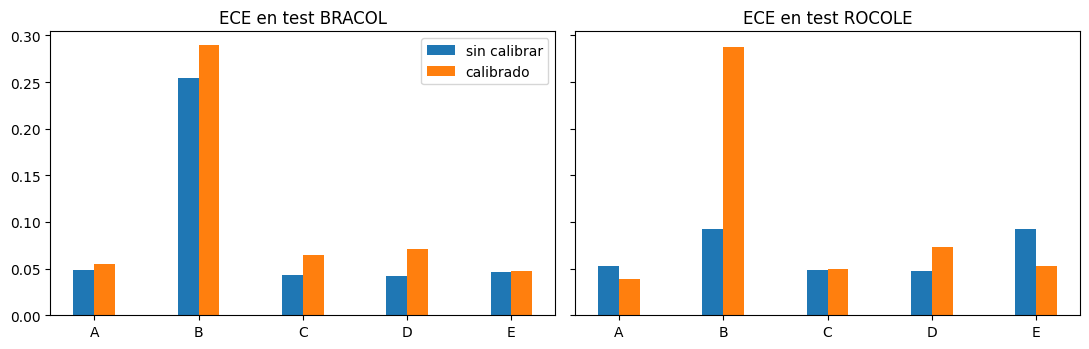

In [8]:
x = np.arange(len(final)); w = 0.2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, ds in zip(axes, ["bracol", "rocole"]):
    ax.bar(x - w/2, final[f"{ds}_ece_sin_calibrar"], w, label="sin calibrar")
    ax.bar(x + w/2, final[f"{ds}_ece_calibrado"], w, label="calibrado")
    ax.set_xticks(x); ax.set_xticklabels([c.split("_")[0] for c in final["candidato"]]); ax.set_title(f"ECE en test {ds.upper()}")
axes[0].legend(); plt.tight_layout(); plt.show()

**La calibración no mejoró de forma consistente el ECE del test** (para el ensamble elegido empeora un poco); con ~240 imágenes el
ECE tiene un ruido de ~0.03. Es una limitación, no una conclusión.

## 5. Matrices de confusión por hoja del candidato elegido (alimentan `P(O|L)`)

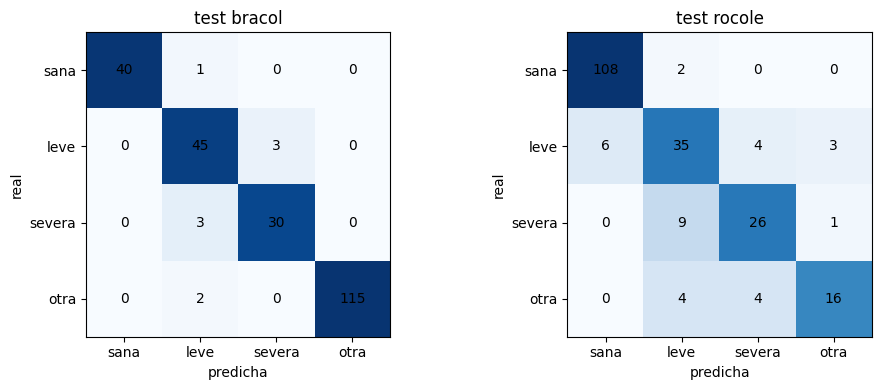

In [9]:
conf = json.load(open(EXP / "confusion_hoja.json", encoding="utf-8"))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, ["test_bracol", "test_rocole"]):
    cm = np.array(conf[key]); ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
    ax.set_xticks(range(4)); ax.set_xticklabels(SHORT); ax.set_yticks(range(4)); ax.set_yticklabels(SHORT)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(key.replace("_", " "))
plt.tight_layout(); plt.show()

In [10]:
def detection(cm):
    cm = np.array(cm); tp = cm[np.ix_([1, 2], [1, 2])].sum(); fn = cm[np.ix_([1, 2], [0, 3])].sum()
    tn = cm[np.ix_([0, 3], [0, 3])].sum(); fp = cm[np.ix_([0, 3], [1, 2])].sum()
    return tp / (tp + fn), tn / (tn + fp), tp + fn, tn + fp
for key in ["test_bracol", "test_rocole"]:
    s, e, ns, ne = detection(conf[key]); print(f"{key}: sensibilidad de roya {s:.3f} (n={ns}), especificidad {e:.3f} (n={ne})")

test_bracol: sensibilidad de roya 1.000 (n=81), especificidad 0.981 (n=158)
test_rocole: sensibilidad de roya 0.881 (n=84), especificidad 0.925 (n=134)


## 6. Grad-CAM: validación sobre los modelos reales

In [11]:
g = json.load(open(EXP / "gradcam_summary.json", encoding="utf-8"))
rows = []
for k, v in g.items():
    rows.append({"modelo|dataset": k, "n": v["imagenes"], "deletion CAM": v["deletion_auc"], "deletion centro": v["centro_deletion_auc"],
                 "deletion azar": v["deletion_auc_aleatorio"], "insertion CAM": v["insertion_auc"],
                 "insertion centro": v["centro_insertion_auc"], "insertion azar": v["insertion_auc_aleatorio"],
                 "CAM>centro (del.)": v["frac_deletion_mejor_que_centro"], "CAM>centro (ins.)": v["frac_insertion_mejor_que_centro"],
                 "cociente fondo": v.get("fondo_cociente_medio", np.nan)})
display(pd.DataFrame(rows).set_index("modelo|dataset").round(3))

,n,deletion CAM,deletion centro,deletion azar,insertion CAM,insertion centro,insertion azar,CAM>centro (del.),CAM>centro (ins.),cociente fondo
modelo|dataset,,,,,,,,,,
efficientnet_b0_dlr_both|bracol,32,0.310,0.423,0.630,0.892,0.820,0.720,0.812,0.844,0.305
efficientnet_b0_dlr_both|rocole,32,0.299,0.384,0.486,0.749,0.713,0.468,0.844,0.750,NaN
resnet18_dlr_both|bracol,32,0.319,0.358,0.534,0.849,0.827,0.675,0.719,0.719,0.376
resnet18_dlr_both|rocole,32,0.345,0.402,0.432,0.700,0.660,0.538,0.688,0.719,NaN


In [12]:
for k, v in g.items():
    print(k, "· Spearman al reiniciar (salida → entrada):", {a: round(b, 2) for a, b in v["spearman_por_etapa"].items()})

efficientnet_b0_dlr_both|bracol · Spearman al reiniciar (salida → entrada): {'+classifier': -0.04, '+features.8': 0.09, '+features.7': 0.27, '+features.6': 0.08, '+features.5': 0.06, '+features.4': 0.07, '+features.3': 0.16, '+features.2': 0.18, '+features.1': 0.0, '+features.0': -0.1}
efficientnet_b0_dlr_both|rocole · Spearman al reiniciar (salida → entrada): {'+classifier': 0.16, '+features.8': 0.05, '+features.7': 0.09, '+features.6': 0.04, '+features.5': 0.06, '+features.4': 0.04, '+features.3': 0.14, '+features.2': 0.13, '+features.1': 0.06, '+features.0': 0.13}
resnet18_dlr_both|bracol · Spearman al reiniciar (salida → entrada): {'+fc': 0.66, '+layer4': -0.1, '+layer3': 0.18, '+layer2': 0.03, '+layer1': 0.01, '+conv1': 0.13}
resnet18_dlr_both|rocole · Spearman al reiniciar (salida → entrada): {'+fc': 0.7, '+layer4': 0.07, '+layer3': 0.01, '+layer2': -0.17, '+layer1': -0.16, '+conv1': -0.02}


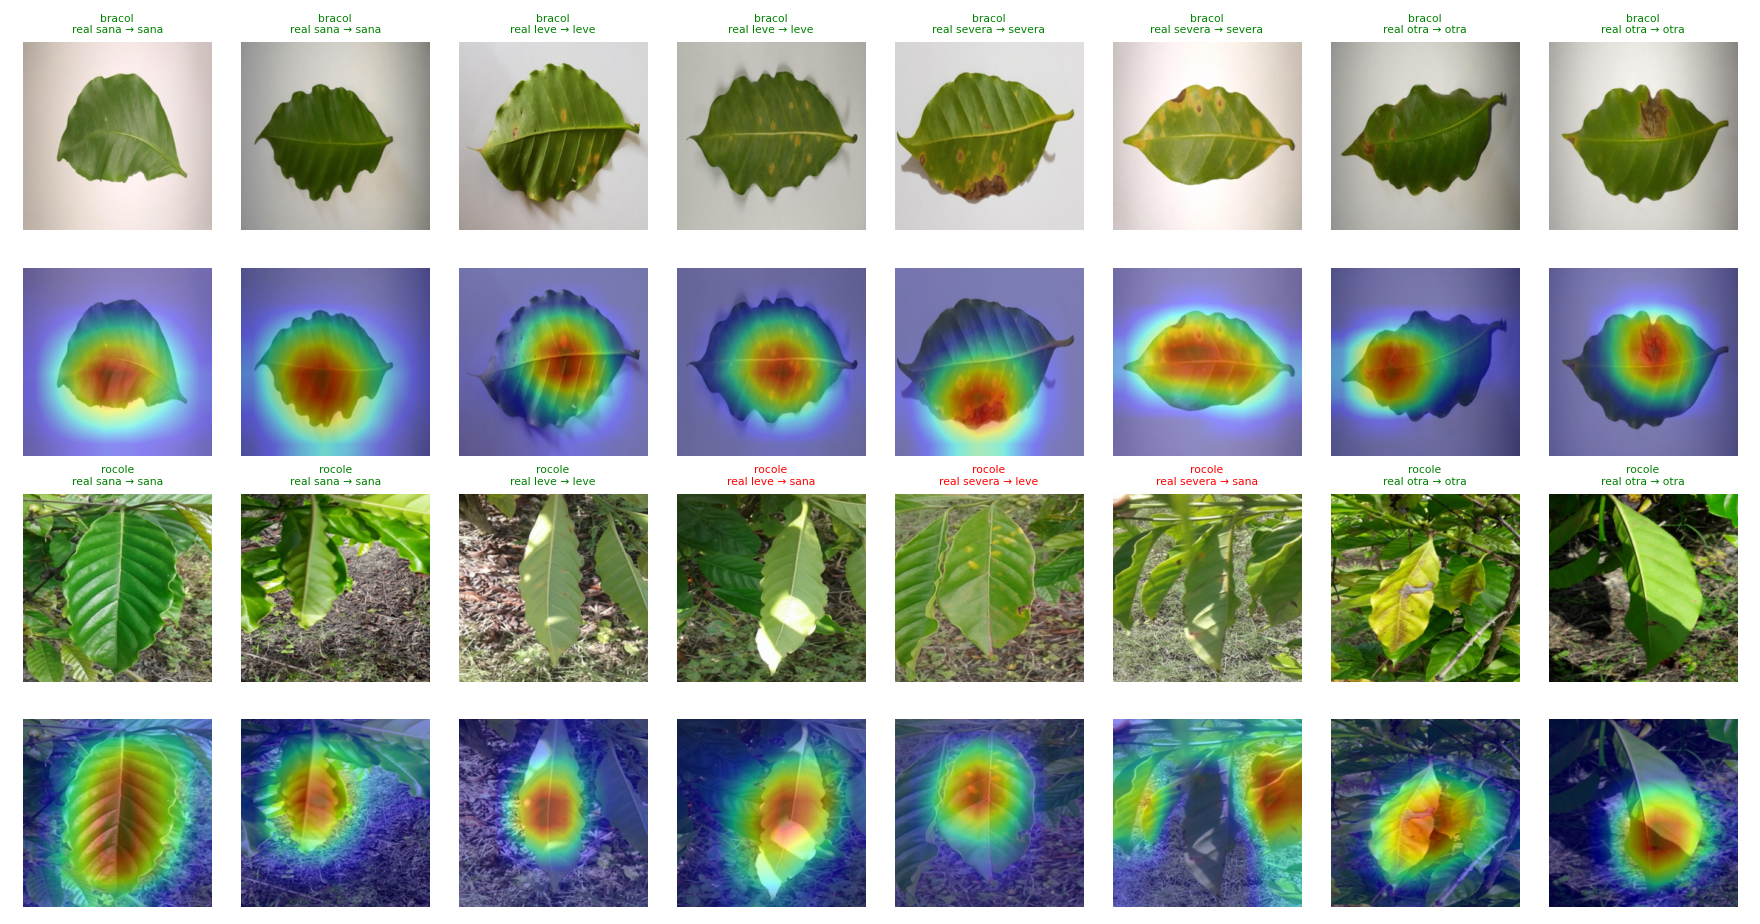

In [13]:
display(Image(filename=str(ROOT / "docs/figures/gradcam_ejemplos_resnet18_dlr_both.png")))

**Lectura.** (1) Pasa la prueba de aleatorización: el mapa depende de lo aprendido. (2) No mira el fondo de BRACOL. (3) Es más
informativo que un orden aleatorio, pero **un mapa fijo centrado explica gran parte de esa ventaja**; el Grad-CAM lo supera en
~70–85 % de las imágenes. (4) Visualmente cubre la hoja de forma amplia; **no localiza pústulas individuales** (resolución 8×8).
No se debe afirmar que el modelo "ve las pústulas".

## 7. Conclusiones y límites

- El candidato final es un **ensamble de 8 modelos** (4 ResNet-18 + 4 EfficientNet-B0 combinados) con detección de roya de
  sensibilidad ≈ 1.0 en BRACOL y ≈ 0.88 en fotos de campo, y especificidad ≈ 0.93–0.98.
- La roya **severa** es la clase débil en campo (recall ≈ 0.72): se confunde con roya leve.
- Resultados con tests pequeños (239 y 218 imágenes) y una sola partición; las fotos de productores serán otro dominio y las
  cifras son una cota optimista.
- Pendiente: temperatura sobre el ensamble completo, validar contra máscaras de lesión (BRACOL trae segmentación) y probar con fotos reales de campo.